# Notebook 7. Ảnh hưởng của seed

Người phụ trách: Nguyễn Trọng Phúc.

Đề yêu cầu kiểm tra ảnh hưởng của seed. Hai phần:
1. **Seed huấn luyện:** huấn luyện lại mạng cấp 5 với 3 seed khác nhau (đổi cả cách chia train/val/test lẫn trọng số khởi tạo), so độ chính xác trên val và test. Mô hình thử lưu vào `files/seed_thu/`, không đè mô hình chính.
2. **Seed ván đấu:** cùng một cặp tác tử có yếu tố ngẫu nhiên (cấp 4 đấu cấp 3, cấu hình mặc định) chạy với 3 seed khác nhau, mỗi seed 100 ván, so score giữa các seed.

Cần có: `files/games_*.p` (nb3). Chạy sau khi các notebook khác đã xong để không làm chậm các mục đo theo thời gian.

In [1]:
# QUICK = True: chạy thử vài ván, vài epoch để kiểm tra code (ghi vào thư mục con thu_nhanh/)
# QUICK = False: chạy thật theo config.yaml, kết quả dùng cho báo cáo
QUICK = False

import os
if not os.path.exists("config.yaml"):
    raise RuntimeError("Hãy mở Jupyter trong thư mục final_connect_four (nơi có config.yaml).")

import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from utils.experiments import setup, summaries_table, with_random_opening, move_times_of
from utils.arena import run_match, format_summary, read_log, first_player_stats
from utils.data import machine_info
import keras
from utils import data, nets, policy_net
ex = setup(QUICK)
cfg = ex.cfg
print("Cấu hình máy:", machine_info())

Chế độ: chạy thật. Log: results/logs\ | Hình: results\figures\ | Mô hình: files\
Cấu hình máy: {'system': 'Windows', 'release': '11', 'processor': 'Intel64 Family 6 Model 154 Stepping 3, GenuineIntel', 'cpu_count': 16, 'python': '3.13.5'}


## 1. Seed huấn luyện của mạng cấp 5

In [2]:
paths = []
for part in cfg["data"]["seeds"]:
    path = ex.model(f"games_{part}.p")
    if os.path.exists(path):
        paths.append(path)
games = data.merge_game_files(paths)
print("Số ván:", len(games))

train_cfg = cfg["train_policy"]
rows = []
for seed in [0, 1, 2]:
    keras.utils.set_random_seed(seed)
    model, report = policy_net.train_policy(games, path=ex.model(f"seed_thu/policy_seed{seed}.keras"),
                                            epochs=ex.n(train_cfg["epochs"], 2),
                                            batch_size=train_cfg["batch_size"],
                                            learning_rate=train_cfg["learning_rate"], seed=seed, verbose=0,
                                            mirror=train_cfg["mirror"], patience=train_cfg["patience"])
    rows.append({"seed": seed, "epoch giữ lại": report["best_epoch"],
                 "val acc": round(report["val_accuracy"], 3), "test acc": round(report["test_accuracy"], 3),
                 "val loss": round(report["val_loss"], 3)})
    print("xong seed", seed)

seed_train = pd.DataFrame(rows)
seed_train.to_csv(ex.table("nb7_seed_huan_luyen.csv"), index=False, encoding="utf-8-sig")
print(f"test acc: trung bình {seed_train['test acc'].mean():.3f}, độ lệch chuẩn {seed_train['test acc'].std():.3f}")
seed_train

Số ván: 3000


xong seed 0


xong seed 1


xong seed 2
test acc: trung bình 0.503, độ lệch chuẩn 0.003


,seed,epoch giữ lại,val acc,test acc,val loss
0,0,5,0.506,0.505,1.192
1,1,4,0.508,0.504,1.241
2,2,4,0.498,0.499,1.206


## 2. Seed ván đấu: cấp 4 đấu cấp 3

In [3]:
n_games = ex.n(100, 4)
log_path = ex.log("nb7_seed_van_dau.jsonl")
cap4 = ex.agent("cap4")
cap3 = ex.agent("cap3")

summaries = []
for k, seed in enumerate([700, 701, 702]):
    # tên cặp có seed để ba lần chạy không trộn vào nhau trong log
    s = run_match(cap4, cap3, f"cap4_seed{seed}", f"cap3_seed{seed}", n_games, seed=seed, log_path=log_path)
    summaries.append(s)
    print(format_summary(s))

seed_games = summaries_table(summaries)
seed_games.insert(0, "seed", [700, 701, 702])
seed_games.to_csv(ex.table("nb7_seed_van_dau.csv"), index=False, encoding="utf-8-sig")
scores = [s["score"] for s in summaries]
print(f"score cấp 4: trung bình {np.mean(scores):.3f}, độ lệch chuẩn {np.std(scores, ddof=1):.3f}")
seed_games

cap4_seed700 vs cap3_seed700: 37-3-60 (thắng-hòa-thua), score 0.385 [0.296, 0.483], thời gian TB 86.4 ms, p95 152.7 ms


cap4_seed701 vs cap3_seed701: 36-0-64 (thắng-hòa-thua), score 0.360 [0.273, 0.458], thời gian TB 92.9 ms, p95 150.0 ms


cap4_seed702 vs cap3_seed702: 25-0-75 (thắng-hòa-thua), score 0.250 [0.175, 0.343], thời gian TB 93.4 ms, p95 150.9 ms
score cấp 4: trung bình 0.332, độ lệch chuẩn 0.072


,seed,tác tử,đối thủ,số ván,thắng,hòa,thua,score,Wilson 95%,TB (ms),p95 (ms),xử thua
0,700,cap4_seed700,cap3_seed700,100,37,3,60,0.385,"[0.296, 0.483]",86.4,152.7,0
1,701,cap4_seed701,cap3_seed701,100,36,0,64,0.360,"[0.273, 0.458]",92.9,150.0,0
2,702,cap4_seed702,cap3_seed702,100,25,0,75,0.250,"[0.175, 0.343]",93.4,150.9,0


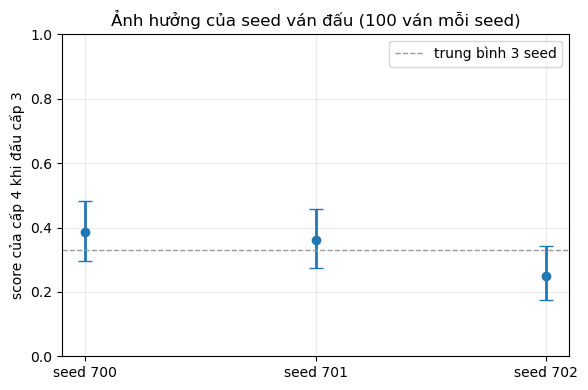

In [4]:
fig, ax = plt.subplots(figsize=(6, 4))
x = np.arange(3)
low = [s["score"] - s["ci_low"] for s in summaries]
high = [s["ci_high"] - s["score"] for s in summaries]
ax.errorbar(x, scores, yerr=[low, high], fmt="o", capsize=5, linewidth=2)
ax.axhline(np.mean(scores), color="#999999", linestyle="--", linewidth=1, label="trung bình 3 seed")
ax.set_xticks(x, ["seed 700", "seed 701", "seed 702"])
ax.set_ylim(0, 1)
ax.set_ylabel("score của cấp 4 khi đấu cấp 3")
ax.set_title("Ảnh hưởng của seed ván đấu (100 ván mỗi seed)")
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig(ex.fig("nb7_seed_van_dau.png"), dpi=150)